Generando Figura 5 (con la implementación corregida)...


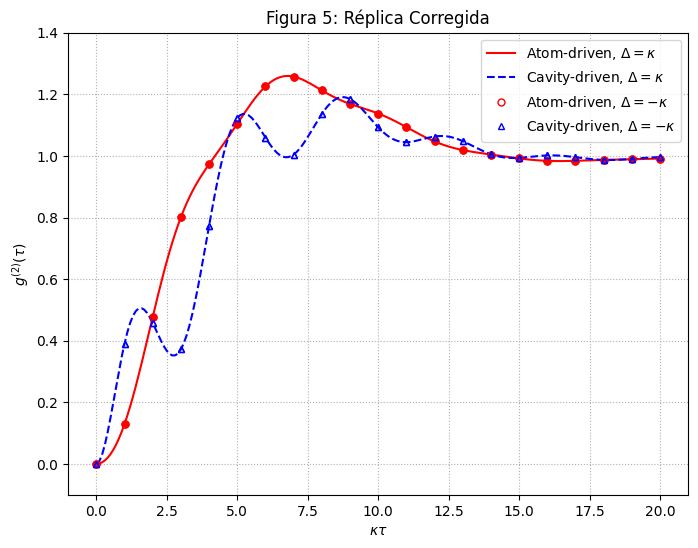

Generando Figura 6...


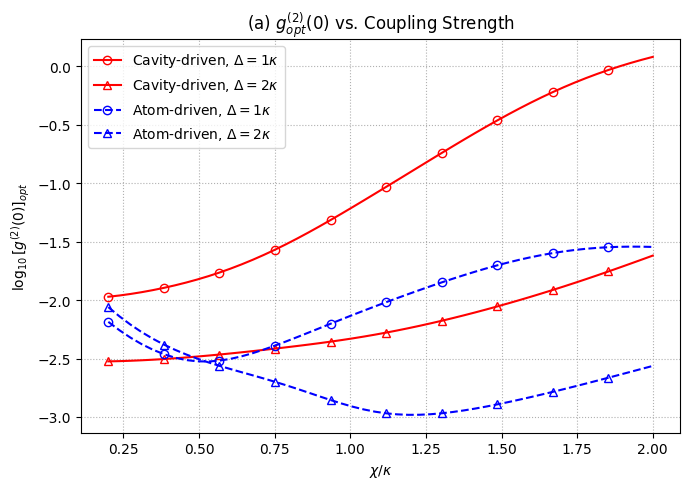

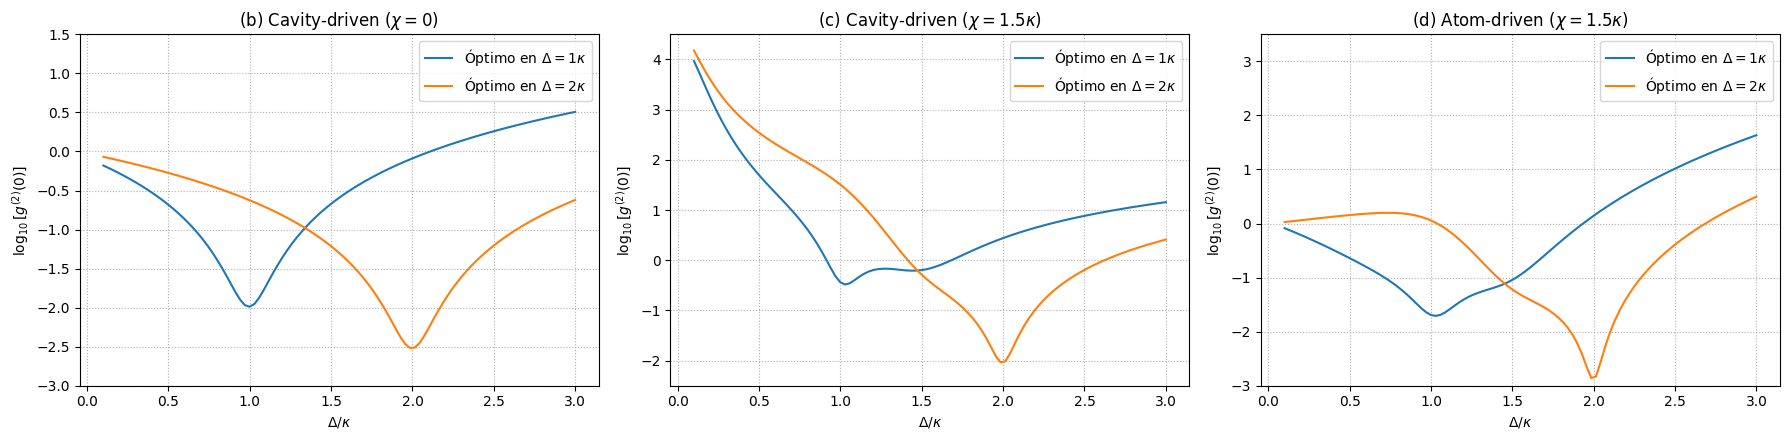

In [ ]:
# =============================================================================
# RECREACIÓN DE FIGURAS DEL ARTÍCULO arXiv:2505.04280v1
# "Unconventional photon blockade in cavity QED with parametric amplification"
#
# Para ejecutar este código, necesita tener instaladas las siguientes librerías:
# pip install numpy matplotlib qutip
# =============================================================================

import numpy as np
import matplotlib.pyplot as plt
from qutip import   tensor, destroy, sigmam, identity, steadystate, expect, mesolve
import qutip

# --- Funciones Auxiliares y Definición del Modelo ---


def get_hamiltonian(delta, chi_val, Lambda, phi, Omega_val, drive_type='cavity', N=5):
    """Construye el Hamiltoniano del sistema."""
    a = qutip.tensor(qutip.destroy(N), qutip.qeye(2))
    sm = qutip.tensor(qutip.qeye(N), qutip.sigmam())
    n_op = a.dag() * a
    
    H0 = delta * n_op + delta * sm.dag() * sm
    H_int = chi_val * (a.dag() * sm + a * sm.dag())
    H_param = Lambda * ((a.dag()**2) * np.exp(-1j * phi) + (a**2) * np.exp(1j * phi))

    if drive_type == 'cavity':
        H_drive = Omega_val * (a.dag() + a)
    elif drive_type == 'atom':
        H_drive = Omega_val * (sm.dag() + sm)
    else:
        raise ValueError("drive_type must be 'cavity' or 'atom'")
        
    return H0 + H_int + H_param + H_drive

def calculate_g2_0(H, c_ops, N=5):
    """Calcula g^(2)(0) en el estado estacionario."""
    rho_ss = qutip.steadystate(H, c_ops, method='direct')
    a = qutip.tensor(qutip.destroy(N), qutip.qeye(2))
    n_ss = qutip.expect(a.dag() * a, rho_ss)
    
    if n_ss < 1e-12:
        return 1.0
        
    g2_0_num = qutip.expect(a.dag() * a.dag() * a * a, rho_ss)
    g2_0 = g2_0_num / (n_ss**2)
    return g2_0

def get_optimal_params_analytical(delta, chi_val, Omega_val, gamma_val, kappa_val, drive_type):
    """Calcula Lambda_opt y phi_opt usando Eqs. (10) y (14) del paper."""
    dc_p = delta - 1j * kappa_val / 2.0
    da_p = delta - 1j * gamma_val / 2.0
    
    den = (da_p + dc_p) * (dc_p * da_p - chi_val**2)
    
    if drive_type == 'cavity':
        num = (chi_val**2 + da_p * (da_p + dc_p)) * Omega_val**2
    else: # atom-driven
        num = chi_val**2 * Omega_val**2
        
    c_val = num / den
    return np.abs(c_val), -np.angle(c_val)

# --- Figura 3 y 4: g^(2)(0) vs. Detuning ---


def plot_figures_3_and_4_final():
    print("Generando Figuras 3 y 4 con múltiples puntos numéricos...")
    kappa = 1.0
    gamma = 0.1
    chi = 1.0 / np.sqrt(2)
    Omega = 0.005
    N = 5
    
    a = qutip.tensor(qutip.destroy(N), qutip.qeye(2))
    sm = qutip.tensor(qutip.qeye(N), qutip.sigmam())
    c_ops = [np.sqrt(kappa) * a, np.sqrt(gamma) * sm]

    # Curvas analíticas (alta resolución)
    delta_vals_curve = np.linspace(-2, 2, 101) * kappa
    # Puntos numéricos (menor resolución para replicar el paper)
    delta_vals_numeric = np.linspace(-2, 2, 21) * kappa
    
    phi_vals_map = np.linspace(-1.0, 0, 101) * np.pi

    # --- Figura 3 (Cavity-Driven) ---
    Lambda_c_opt_fig = 4.239e-5 * kappa
    phi_c_plus_opt = -0.277 * np.pi
    phi_c_minus_opt = -0.723 * np.pi

    # Calcular curvas analíticas
    g2_c_plus_curve = [calculate_g2_0(get_hamiltonian(d, chi, Lambda_c_opt_fig, phi_c_plus_opt, Omega, 'cavity', N), c_ops, N) for d in delta_vals_curve]
    g2_c_minus_curve = [calculate_g2_0(get_hamiltonian(d, chi, Lambda_c_opt_fig, phi_c_minus_opt, Omega, 'cavity', N), c_ops, N) for d in delta_vals_curve]
    
    # *** Calcular puntos numéricos discretos ***
    g2_c_plus_numeric = [calculate_g2_0(get_hamiltonian(d, chi, Lambda_c_opt_fig, phi_c_plus_opt, Omega, 'cavity', N), c_ops, N) for d in delta_vals_numeric]
    g2_c_minus_numeric = [calculate_g2_0(get_hamiltonian(d, chi, Lambda_c_opt_fig, phi_c_minus_opt, Omega, 'cavity', N), c_ops, N) for d in delta_vals_numeric]

    # Calcular mapa de color
    g2_c_grid = np.array([[calculate_g2_0(get_hamiltonian(d, chi, Lambda_c_opt_fig, p, Omega, 'cavity', N), c_ops, N) for d in delta_vals_curve] for p in phi_vals_map])

    # Graficar Figura 3
    fig3, (ax3a, ax3b) = plt.subplots(2, 1, figsize=(6, 8.5), gridspec_kw={'height_ratios': [1, 1.5]})
    fig3.suptitle('Figura 3 Recreada: Cavity-Driven Case', fontsize=14)
    ax3a.plot(delta_vals_curve / kappa, np.log10(g2_c_plus_curve), 'r-', label=r'Analítico ($\Lambda^{opt}_{+}, \phi^{opt}_{+}$)')
    ax3a.plot(delta_vals_curve / kappa, np.log10(g2_c_minus_curve), 'b--', label=r'Analítico ($\Lambda^{opt}_{-}, \phi^{opt}_{-}$)')
    ax3a.plot(delta_vals_numeric / kappa, np.log10(g2_c_plus_numeric), 'ro', markersize=6, mfc='none', label=r'Numérico ($\Lambda^{opt}_{+}, \phi^{opt}_{+}$)')
    ax3a.plot(delta_vals_numeric / kappa, np.log10(g2_c_minus_numeric), 'b^', markersize=6, mfc='none', label=r'Numérico ($\Lambda^{opt}_{-}, \phi^{opt}_{-}$)')
    ax3a.set_ylabel(r'$\log_{10}[g^{(2)}(0)]$'); ax3a.set_ylim(-4.5, 4.5); ax3a.legend(); ax3a.grid(True, ls=':')
    im3 = ax3b.pcolormesh(delta_vals_curve/kappa, phi_vals_map/np.pi, np.log10(g2_c_grid), cmap='jet', vmin=-3, vmax=4.5, shading='auto')
    ax3b.set_xlabel(r'$\Delta/\kappa$'); ax3b.set_ylabel(r'$\phi/\pi$')
    cbar3 = fig3.colorbar(im3, ax=ax3b); cbar3.set_label(r'$\log_{10}[g^{(2)}(0)]$')
    plt.tight_layout(rect=[0, 0, 1, 0.96]); plt.show()

    # --- Figura 4 (Atom-Driven) ---
    Lambda_a_opt_fig = 8.292e-6 * kappa
    phi_a_plus_opt = -0.359 * np.pi
    phi_a_minus_opt = -0.641 * np.pi

    # Calcular curvas analíticas
    g2_a_plus_curve = [calculate_g2_0(get_hamiltonian(d, chi, Lambda_a_opt_fig, phi_a_plus_opt, Omega, 'atom', N), c_ops, N) for d in delta_vals_curve]
    g2_a_minus_curve = [calculate_g2_0(get_hamiltonian(d, chi, Lambda_a_opt_fig, phi_a_minus_opt, Omega, 'atom', N), c_ops, N) for d in delta_vals_curve]
    
    # *** Calcular puntos numéricos discretos ***
    g2_a_plus_numeric = [calculate_g2_0(get_hamiltonian(d, chi, Lambda_a_opt_fig, phi_a_plus_opt, Omega, 'atom', N), c_ops, N) for d in delta_vals_numeric]
    g2_a_minus_numeric = [calculate_g2_0(get_hamiltonian(d, chi, Lambda_a_opt_fig, phi_a_minus_opt, Omega, 'atom', N), c_ops, N) for d in delta_vals_numeric]
    
    # Calcular mapa de color
    g2_a_grid = np.array([[calculate_g2_0(get_hamiltonian(d, chi, Lambda_a_opt_fig, p, Omega, 'atom', N), c_ops, N) for d in delta_vals_curve] for p in phi_vals_map])

    # Graficar Figura 4
    fig4, (ax4a, ax4b) = plt.subplots(2, 1, figsize=(6, 8.5), gridspec_kw={'height_ratios': [1, 1.5]})
    fig4.suptitle('Figura 4 Recreada: Atom-Driven Case', fontsize=14)
    ax4a.plot(delta_vals_curve/kappa, np.log10(g2_a_plus_curve), 'r-', label=r'Analítico ($\Lambda^{opt}_{+}, \phi^{opt}_{+}$)')
    ax4a.plot(delta_vals_curve/kappa, np.log10(g2_a_minus_curve), 'b--', label=r'Analítico ($\Lambda^{opt}_{-}, \phi^{opt}_{-}$)')
    ax4a.plot(delta_vals_numeric / kappa, np.log10(g2_a_plus_numeric), 'ro', markersize=6, mfc='none', label=r'Numérico ($\Lambda^{opt}_{+}, \phi^{opt}_{+}$)')
    ax4a.plot(delta_vals_numeric / kappa, np.log10(g2_a_minus_numeric), 'b^', markersize=6, mfc='none', label=r'Numérico ($\Lambda^{opt}_{-}, \phi^{opt}_{-}$)')
    ax4a.set_ylabel(r'$\log_{10}[g^{(2)}(0)]$'); ax4a.set_ylim(-4.5, 1.5); ax4a.legend(); ax4a.grid(True, ls=':')
    im4 = ax4b.pcolormesh(delta_vals_curve/kappa, phi_vals_map/np.pi, np.log10(g2_a_grid), cmap='jet', vmin=-4, vmax=1, shading='auto')
    ax4b.set_xlabel(r'$\Delta/\kappa$'); ax4b.set_ylabel(r'$\phi/\pi$')
    cbar4 = fig4.colorbar(im4, ax=ax4b); cbar4.set_label(r'$\log_{10}[g^{(2)}(0)]$')
    plt.tight_layout(rect=[0, 0, 1, 0.96]); plt.show()

# --- Figura 5: Correlación de Segundo Orden en dos Tiempos g^(2)(tau) ---

def calculate_g2_tau_corrected(H, taulist, c_ops, a_op, n_op):
    """
    Calcula g^(2)(tau) manualmente usando el Teorema de Regresión Cuántica.
    Esta es la implementación clara y físicamente intuitiva proporcionada por el usuario.
    """
    rho_ss = qutip.steadystate(H, c_ops)
    n_ss = qutip.expect(n_op, rho_ss)
    
    if n_ss < 1e-12:
        return np.ones_like(taulist)
    
    # Estado del sistema justo después de la detección de un fotón
    rho_post_measurement = a_op * rho_ss * a_op.dag()
    
    # Normalizar para obtener el estado condicional inicial para la evolución
    rho0 = rho_post_measurement / n_ss
    
    # Evolucionar este estado y calcular la expectación de encontrar otro fotón
    result = qutip.mesolve(H, rho0, taulist, c_ops, [n_op])
    
    # La función de correlación es la probabilidad condicional normalizada
    g2_t = result.expect[0] / n_ss
    return g2_t

def plot_figure_5_corrected():
    """
    Genera la Figura 5 usando la lógica de cálculo manual corregida.
    """
    print("Generando Figura 5 (con la implementación corregida)...")
    
    # --- Parámetros ---
    kappa = 1.0
    gamma = 0.1
    chi = 1.0 / np.sqrt(2)
    Omega = 0.005
    N = 5
    tau_list = np.linspace(0, 20 / kappa, 201)

    # --- Operadores ---
    a = qutip.tensor(qutip.destroy(N), qutip.qeye(2))
    sm = qutip.tensor(qutip.qeye(N), qutip.sigmam())
    n_op = a.dag() * a
    c_ops = [np.sqrt(kappa) * a, np.sqrt(gamma) * sm]

    # --- Cálculos para los 4 casos ---
    
    # 1. Átomo accionado, Delta = +kappa
    delta = kappa
    Lambda, phi = get_optimal_params_analytical(delta, chi, Omega, gamma, kappa, 'atom')
    H = get_hamiltonian(delta, chi, Lambda, phi, Omega, 'atom', N)
    g2_a_p = calculate_g2_tau_corrected(H, tau_list, c_ops, a, n_op)

    # 2. Cavidad accionada, Delta = +kappa
    delta = kappa
    Lambda, phi = get_optimal_params_analytical(delta, chi, Omega, gamma, kappa, 'cavity')
    H = get_hamiltonian(delta, chi, Lambda, phi, Omega, 'cavity', N)
    g2_c_p = calculate_g2_tau_corrected(H, tau_list, c_ops, a, n_op)
    
    # 3. Átomo accionado, Delta = -kappa
    delta = -kappa
    Lambda, phi = get_optimal_params_analytical(delta, chi, Omega, gamma, kappa, 'atom')
    H = get_hamiltonian(delta, chi, Lambda, phi, Omega, 'atom', N)
    g2_a_m = calculate_g2_tau_corrected(H, tau_list, c_ops, a, n_op)

    # 4. Cavidad accionada, Delta = -kappa
    delta = -kappa
    Lambda, phi = get_optimal_params_analytical(delta, chi, Omega, gamma, kappa, 'cavity')
    H = get_hamiltonian(delta, chi, Lambda, phi, Omega, 'cavity', N)
    g2_c_m = calculate_g2_tau_corrected(H, tau_list, c_ops, a, n_op)

    # --- Gráfico (replicando el estilo del paper) ---
    plt.figure("Figura 5 - Réplica Corregida", figsize=(8, 6))
    
    # Caso Atom-driven, Delta = kappa (línea sólida roja con círculos)
    plt.plot(kappa * tau_list, g2_a_p, 'r-', label=r'Atom-driven, $\Delta=\kappa$')
    plt.plot(kappa * tau_list[::10], g2_a_p[::10], 'ro', markersize=5) # Añadir marcadores
    
    # Caso Cavity-driven, Delta = kappa (línea discontinua azul con triángulos)
    plt.plot(kappa * tau_list, g2_c_p, 'b--', label=r'Cavity-driven, $\Delta=\kappa$')
    plt.plot(kappa * tau_list[::10], g2_c_p[::10], 'b^', markersize=5, mfc='none') # Añadir marcadores
    
    # La leyenda del paper es un poco ambigua. Para replicar los marcadores:
    # Atom-driven, D=-k (Círculos rojos)
    # Cavity-driven, D=-k (Triángulos azules)
    # Se superponen con las curvas existentes. Añadimos solo los marcadores para claridad.
    plt.plot(kappa * tau_list[::10], g2_a_m[::10], 'ro', markersize=5, mfc='none', label=r'Atom-driven, $\Delta=-\kappa$')
    plt.plot(kappa * tau_list[::10], g2_c_m[::10], 'b^', markersize=5, mfc='none', label=r'Cavity-driven, $\Delta=-\kappa$')

    plt.title("Figura 5")
    plt.xlabel(r"$\kappa\tau$")
    plt.ylabel(r"$g^{(2)}(\tau)$")
    plt.legend()
    plt.grid(True, linestyle=':')
    plt.ylim(-0.1, 1.4)
    plt.show()

# --- Figura 6: Análisis de Parámetros Adicional ---
def plot_figure_6():
    print("Generando Figura 6...")
    kappa = 1.0
    gamma = 0.1
    Omega = 0.04 # Nuevo Omega para esta figura
    N = 6 # Aumentar N para Omega más grande
    
    a = tensor(destroy(N), identity(2))
    sm = tensor(identity(N), sigmam())
    
    # --- Figura 6(a) ---
    chi_vals = np.linspace(0.2, 2.0, 50) * kappa
    deltas_to_plot = [1.0 * kappa, 2.0 * kappa]
    
    fig6a, ax6a = plt.subplots(figsize=(7, 5))
    styles = {'cavity': {'color': 'r', 'ls': '-'}, 'atom': {'color': 'b', 'ls': '--'}}
    markers = {1.0*kappa: 'o', 2.0*kappa: '^'}
    
    for drive in ['cavity', 'atom']:
        for delta in deltas_to_plot:
            g2_opt_vals = []
            for chi in chi_vals:
                Lambda_opt, phi_opt = get_optimal_params_analytical(delta, chi, Omega, gamma, kappa, drive)
                H = get_hamiltonian(delta, chi, Lambda_opt, phi_opt, Omega, drive, N)
                c_ops = [np.sqrt(kappa) * a, np.sqrt(gamma) * sm]
                g2_opt_vals.append(calculate_g2_0(H, c_ops, N))
            
            label = f"{drive.capitalize()}-driven, $\Delta={int(delta/kappa)}\kappa$"
            ax6a.plot(chi_vals/kappa, np.log10(g2_opt_vals), color=styles[drive]['color'], ls=styles[drive]['ls'], 
                      marker=markers[delta], markevery=5, mfc='none', label=label)

    ax6a.set_xlabel(r'$\chi/\kappa$'); ax6a.set_ylabel(r'$\log_{10}[g^{(2)}(0)]_{opt}$'); ax6a.set_title('(a) $g^{(2)}_{opt}(0)$ vs. Coupling Strength')
    ax6a.legend(); ax6a.grid(True, ls=':'); plt.tight_layout(); plt.show()
    
    # --- Figura 6(b), (c), (d) ---
    fig6bcd, axes = plt.subplots(1, 3, figsize=(18, 4.5))
    delta_vals_scan = np.linspace(0.1, 3.0, 101) * kappa

    # (b) Cavity-driven, chi = 0
    chi_b = 0.0
    c_ops_b = [np.sqrt(kappa) * a, np.sqrt(gamma) * sm]
    for delta_opt in [1.0*kappa, 2.0*kappa]:
        L_opt, p_opt = get_optimal_params_analytical(delta_opt, chi_b, Omega, gamma, kappa, 'cavity')
        g2_vals = [calculate_g2_0(get_hamiltonian(d, chi_b, L_opt, p_opt, Omega, 'cavity', N), c_ops_b, N) for d in delta_vals_scan]
        axes[0].plot(delta_vals_scan/kappa, np.log10(g2_vals), label=f'Óptimo en $\Delta={int(delta_opt/kappa)}\kappa$')
    axes[0].set_title(r'(b) Cavity-driven ($\chi=0$)'); axes[0].set_ylim(-3, 1.5)

    # (c) Cavity-driven, chi = 1.5k
    chi_c = 1.5 * kappa
    c_ops_c = [np.sqrt(kappa) * a, np.sqrt(gamma) * sm]
    for delta_opt in [1.0*kappa, 2.0*kappa]:
        L_opt, p_opt = get_optimal_params_analytical(delta_opt, chi_c, Omega, gamma, kappa, 'cavity')
        g2_vals = [calculate_g2_0(get_hamiltonian(d, chi_c, L_opt, p_opt, Omega, 'cavity', N), c_ops_c, N) for d in delta_vals_scan]
        axes[1].plot(delta_vals_scan/kappa, np.log10(g2_vals), label=f'Óptimo en $\Delta={int(delta_opt/kappa)}\kappa$')
    axes[1].set_title(r'(c) Cavity-driven ($\chi=1.5\kappa$)'); axes[1].set_ylim(-2.5, 4.5)

    # (d) Atom-driven, chi = 1.5k
    chi_d = 1.5 * kappa
    c_ops_d = [np.sqrt(kappa) * a, np.sqrt(gamma) * sm]
    for delta_opt in [1.0*kappa, 2.0*kappa]:
        L_opt, p_opt = get_optimal_params_analytical(delta_opt, chi_d, Omega, gamma, kappa, 'atom')
        g2_vals = [calculate_g2_0(get_hamiltonian(d, chi_d, L_opt, p_opt, Omega, 'atom', N), c_ops_d, N) for d in delta_vals_scan]
        axes[2].plot(delta_vals_scan/kappa, np.log10(g2_vals), label=f'Óptimo en $\Delta={int(delta_opt/kappa)}\kappa$')
    axes[2].set_title(r'(d) Atom-driven ($\chi=1.5\kappa$)'); axes[2].set_ylim(-3, 3.5)

    for ax in axes:
        ax.set_xlabel(r'$\Delta/\kappa$'); ax.set_ylabel(r'$\log_{10}[g^{(2)}(0)]$'); ax.legend(); ax.grid(True, ls=':')
    plt.tight_layout(); plt.show()


# --- Ejecución Principal ---
if __name__ == '__main__':
    #plot_figures_3_and_4_final()
    plot_figure_5_corrected()
    #plot_figure_6()

Generando Figuras 3 y 4 con múltiples puntos numéricos...


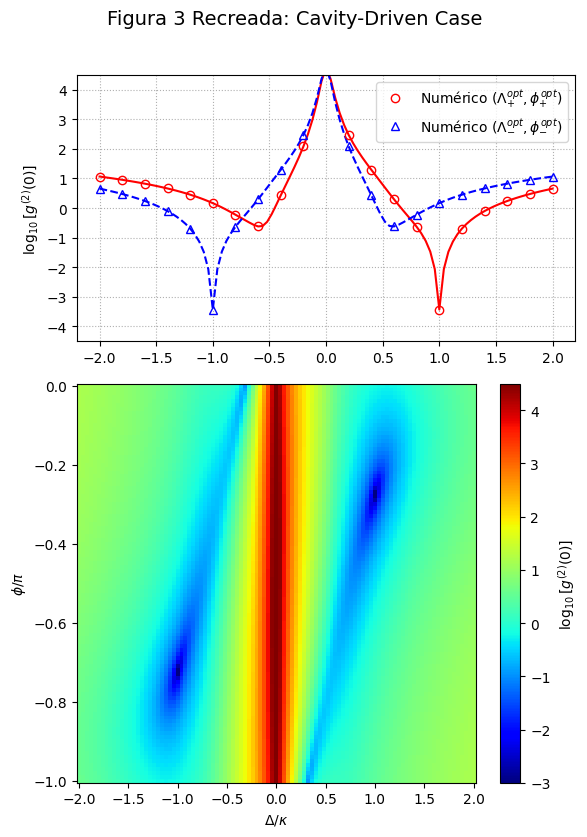

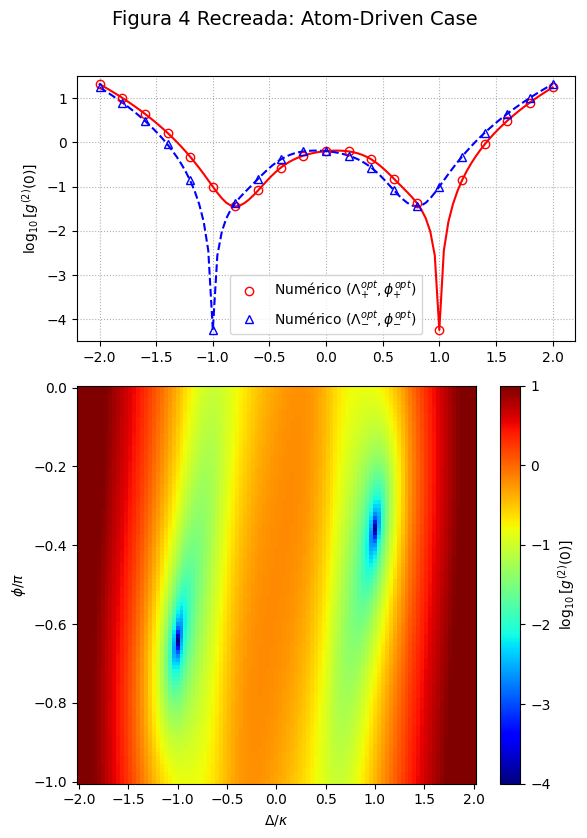

Generando Figura 6 con notación LaTeX...


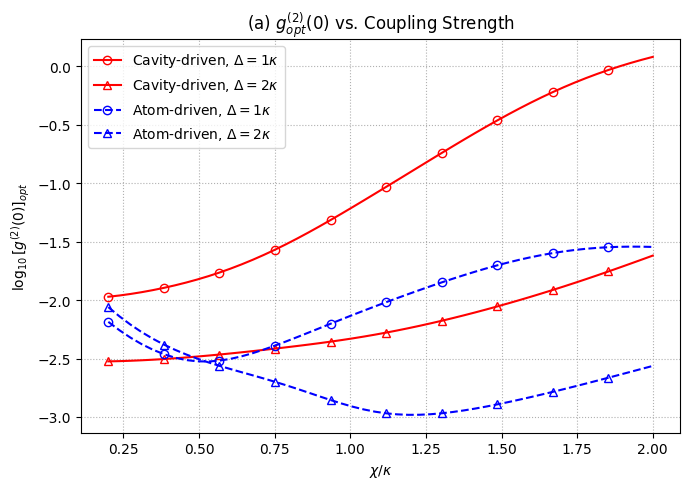

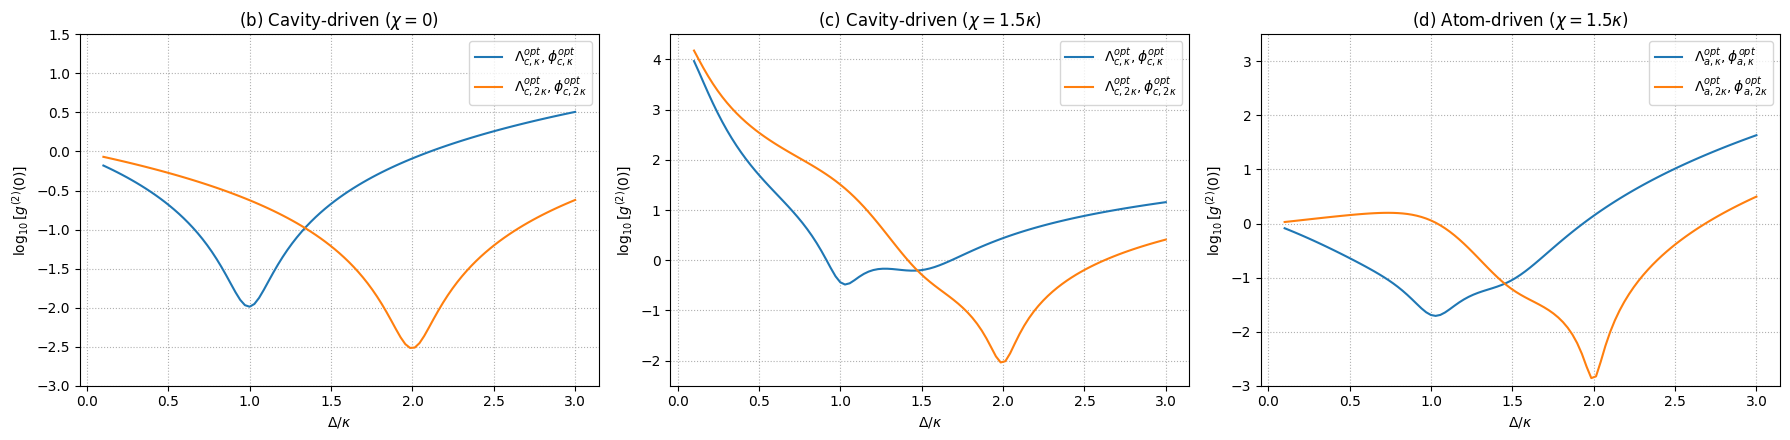

In [16]:
# =============================================================================
# RECREACIÓN DE FIGURAS DEL ARTÍCULO arXiv:2505.04280v1
# "Unconventional photon blockade in cavity QED with parametric amplification"
# =============================================================================

import numpy as np
import matplotlib.pyplot as plt
import qutip

# --- Funciones Auxiliares y Definición del Modelo ---

def get_hamiltonian(delta, chi_val, Lambda, phi, Omega_val, drive_type='cavity', N=5):
    """Construye el Hamiltoniano del sistema."""
    a = qutip.tensor(qutip.destroy(N), qutip.qeye(2))
    sm = qutip.tensor(qutip.qeye(N), qutip.sigmam())
    n_op = a.dag() * a
    
    H0 = delta * n_op + delta * sm.dag() * sm
    H_int = chi_val * (a.dag() * sm + a * sm.dag())
    H_param = Lambda * ((a.dag()**2) * np.exp(-1j * phi) + (a**2) * np.exp(1j * phi))

    if drive_type == 'cavity':
        H_drive = Omega_val * (a.dag() + a)
    elif drive_type == 'atom':
        H_drive = Omega_val * (sm.dag() + sm)
    else:
        raise ValueError("drive_type must be 'cavity' or 'atom'")
        
    return H0 + H_int + H_param + H_drive

def calculate_g2_0(H, c_ops, N=5):
    """Calcula g^(2)(0) en el estado estacionario."""
    rho_ss = qutip.steadystate(H, c_ops, method='direct')
    a = qutip.tensor(qutip.destroy(N), qutip.qeye(2))
    n_ss = qutip.expect(a.dag() * a, rho_ss)
    
    if n_ss < 1e-12: return 1.0
        
    g2_0_num = qutip.expect(a.dag() * a.dag() * a * a, rho_ss)
    return g2_0_num / (n_ss**2)

def get_optimal_params_analytical(delta, chi_val, Omega_val, gamma_val, kappa_val, drive_type):
    """Calcula Lambda_opt y phi_opt usando Eqs. (10) y (14) del paper."""
    dc_p = delta - 1j * kappa_val / 2.0
    da_p = delta - 1j * gamma_val / 2.0
    den = (da_p + dc_p) * (dc_p * da_p - chi_val**2)
    
    if drive_type == 'cavity':
        num = (chi_val**2 + da_p * (da_p + dc_p)) * Omega_val**2
    else:
        num = chi_val**2 * Omega_val**2
        
    if den == 0: return 0, 0
    c_val = num / den
    return np.abs(c_val), -np.angle(c_val)

def plot_figures_3_and_4():
    print("Generando Figuras 3 y 4 con múltiples puntos numéricos...")
    kappa, gamma, chi, Omega, N = 1.0, 0.1, 1.0/np.sqrt(2), 0.005, 5
    a = qutip.tensor(qutip.destroy(N), qutip.qeye(2))
    sm = qutip.tensor(qutip.qeye(N), qutip.sigmam())
    c_ops = [np.sqrt(kappa) * a, np.sqrt(gamma) * sm]
    delta_curve = np.linspace(-2, 2, 101) * kappa
    delta_numeric = np.linspace(-2, 2, 21) * kappa
    phi_map = np.linspace(-1.0, 0, 101) * np.pi

    # Fig 3
    L_c, p_c_p, p_c_m = 4.239e-5*kappa, -0.277*np.pi, -0.723*np.pi
    g2_c_p_curve = [calculate_g2_0(get_hamiltonian(d, chi, L_c, p_c_p, Omega, 'cavity', N), c_ops, N) for d in delta_curve]
    g2_c_m_curve = [calculate_g2_0(get_hamiltonian(d, chi, L_c, p_c_m, Omega, 'cavity', N), c_ops, N) for d in delta_curve]
    g2_c_p_num = [calculate_g2_0(get_hamiltonian(d, chi, L_c, p_c_p, Omega, 'cavity', N), c_ops, N) for d in delta_numeric]
    g2_c_m_num = [calculate_g2_0(get_hamiltonian(d, chi, L_c, p_c_m, Omega, 'cavity', N), c_ops, N) for d in delta_numeric]
    g2_c_grid = np.array([[calculate_g2_0(get_hamiltonian(d, chi, L_c, p, Omega, 'cavity', N), c_ops, N) for d in delta_curve] for p in phi_map])
    fig3, (ax3a, ax3b) = plt.subplots(2, 1, figsize=(6, 8.5), gridspec_kw={'height_ratios': [1, 1.5]})
    fig3.suptitle('Figura 3 Recreada: Cavity-Driven Case', fontsize=14)
    ax3a.plot(delta_curve/kappa, np.log10(g2_c_p_curve), 'r-'); ax3a.plot(delta_curve/kappa, np.log10(g2_c_m_curve), 'b--')
    ax3a.plot(delta_numeric/kappa, np.log10(g2_c_p_num), 'ro', ms=6, mfc='none', label='Numérico ($\Lambda^{opt}_{+}, \phi^{opt}_{+}$)')
    ax3a.plot(delta_numeric/kappa, np.log10(g2_c_m_num), 'b^', ms=6, mfc='none', label='Numérico ($\Lambda^{opt}_{-}, \phi^{opt}_{-}$)')
    ax3a.set_ylabel(r'$\log_{10}[g^{(2)}(0)]$'); ax3a.set_ylim(-4.5, 4.5); ax3a.legend(); ax3a.grid(True, ls=':')
    im3 = ax3b.pcolormesh(delta_curve/kappa, phi_map/np.pi, np.log10(g2_c_grid), cmap='jet', vmin=-3, vmax=4.5, shading='auto')
    ax3b.set_xlabel(r'$\Delta/\kappa$'); ax3b.set_ylabel(r'$\phi/\pi$'); fig3.colorbar(im3, ax=ax3b).set_label(r'$\log_{10}[g^{(2)}(0)]$')
    plt.tight_layout(rect=[0, 0, 1, 0.96]); plt.show()

    # Fig 4
    L_a, p_a_p, p_a_m = 8.292e-6*kappa, -0.359*np.pi, -0.641*np.pi
    g2_a_p_curve = [calculate_g2_0(get_hamiltonian(d, chi, L_a, p_a_p, Omega, 'atom', N), c_ops, N) for d in delta_curve]
    g2_a_m_curve = [calculate_g2_0(get_hamiltonian(d, chi, L_a, p_a_m, Omega, 'atom', N), c_ops, N) for d in delta_curve]
    g2_a_p_num = [calculate_g2_0(get_hamiltonian(d, chi, L_a, p_a_p, Omega, 'atom', N), c_ops, N) for d in delta_numeric]
    g2_a_m_num = [calculate_g2_0(get_hamiltonian(d, chi, L_a, p_a_m, Omega, 'atom', N), c_ops, N) for d in delta_numeric]
    g2_a_grid = np.array([[calculate_g2_0(get_hamiltonian(d, chi, L_a, p, Omega, 'atom', N), c_ops, N) for d in delta_curve] for p in phi_map])
    fig4, (ax4a, ax4b) = plt.subplots(2, 1, figsize=(6, 8.5), gridspec_kw={'height_ratios': [1, 1.5]})
    fig4.suptitle('Figura 4 Recreada: Atom-Driven Case', fontsize=14)
    ax4a.plot(delta_curve/kappa, np.log10(g2_a_p_curve), 'r-'); ax4a.plot(delta_curve/kappa, np.log10(g2_a_m_curve), 'b--')
    ax4a.plot(delta_numeric/kappa, np.log10(g2_a_p_num), 'ro', ms=6, mfc='none', label='Numérico ($\Lambda^{opt}_{+}, \phi^{opt}_{+}$)')
    ax4a.plot(delta_numeric/kappa, np.log10(g2_a_m_num), 'b^', ms=6, mfc='none', label='Numérico ($\Lambda^{opt}_{-}, \phi^{opt}_{-}$)')
    ax4a.set_ylabel(r'$\log_{10}[g^{(2)}(0)]$'); ax4a.set_ylim(-4.5, 1.5); ax4a.legend(); ax4a.grid(True, ls=':')
    im4 = ax4b.pcolormesh(delta_curve/kappa, phi_map/np.pi, np.log10(g2_a_grid), cmap='jet', vmin=-4, vmax=1, shading='auto')
    ax4b.set_xlabel(r'$\Delta/\kappa$'); ax4b.set_ylabel(r'$\phi/\pi$'); fig4.colorbar(im4, ax=ax4b).set_label(r'$\log_{10}[g^{(2)}(0)]$')
    plt.tight_layout(rect=[0, 0, 1, 0.96]); plt.show()

# --- FIGURA 6 ---

def plot_figure_6():
    print("Generando Figura 6 con notación LaTeX...")
    kappa, gamma, Omega, N = 1.0, 0.1, 0.04, 6
    a = qutip.tensor(qutip.destroy(N), qutip.qeye(2))
    sm = qutip.tensor(qutip.qeye(N), qutip.sigmam())
    
    # --- Figura 6(a) ---
    chi_vals = np.linspace(0.2, 2.0, 50) * kappa
    deltas_to_plot = [1.0 * kappa, 2.0 * kappa]
    fig6a, ax6a = plt.subplots(figsize=(7, 5))
    styles = {'cavity': {'color': 'r', 'ls': '-'}, 'atom': {'color': 'b', 'ls': '--'}}
    markers = {1.0*kappa: 'o', 2.0*kappa: '^'}
    
    for drive in ['cavity', 'atom']:
        for delta in deltas_to_plot:
            g2_opt_vals = [calculate_g2_0(
                get_hamiltonian(delta, chi, *get_optimal_params_analytical(delta, chi, Omega, gamma, kappa, drive), Omega, drive, N),
                [np.sqrt(kappa) * a, np.sqrt(gamma) * sm], N) for chi in chi_vals]
            label = f"{drive.capitalize()}-driven, $\Delta={int(delta/kappa)}\kappa$"
            ax6a.plot(chi_vals/kappa, np.log10(g2_opt_vals), color=styles[drive]['color'], ls=styles[drive]['ls'], 
                      marker=markers[delta], markevery=5, mfc='none', label=label)
    ax6a.set_xlabel(r'$\chi/\kappa$'); ax6a.set_ylabel(r'$\log_{10}[g^{(2)}(0)]_{opt}$'); ax6a.set_title('(a) $g^{(2)}_{opt}(0)$ vs. Coupling Strength')
    ax6a.legend(); ax6a.grid(True, ls=':'); plt.tight_layout(); plt.show()
    
    # --- Figura 6(b), (c), (d) ---
    fig6bcd, axes = plt.subplots(1, 3, figsize=(18, 4.5))
    delta_vals_scan = np.linspace(0.1, 3.0, 101) * kappa
    c_ops = [np.sqrt(kappa) * a, np.sqrt(gamma) * sm]

    # (b) Cavity-driven, chi = 0
    chi_b = 0.0
    for delta_opt in [1.0*kappa, 2.0*kappa]:
        L_opt, p_opt = get_optimal_params_analytical(delta_opt, chi_b, Omega, gamma, kappa, 'cavity')
        g2_vals = [calculate_g2_0(get_hamiltonian(d, chi_b, L_opt, p_opt, Omega, 'cavity', N), c_ops, N) for d in delta_vals_scan]
        subscript = fr'{int(delta_opt/kappa)}\kappa' if delta_opt/kappa > 1 else r'\kappa'
        label = fr'$\Lambda^{{opt}}_{{c,{subscript}}}, \phi^{{opt}}_{{c,{subscript}}}$'
        axes[0].plot(delta_vals_scan/kappa, np.log10(g2_vals), label=label)
    axes[0].set_title(r'(b) Cavity-driven ($\chi=0$)'); axes[0].set_ylim(-3, 1.5)

    # (c) Cavity-driven, chi = 1.5k
    chi_c = 1.5 * kappa
    for delta_opt in [1.0*kappa, 2.0*kappa]:
        L_opt, p_opt = get_optimal_params_analytical(delta_opt, chi_c, Omega, gamma, kappa, 'cavity')
        g2_vals = [calculate_g2_0(get_hamiltonian(d, chi_c, L_opt, p_opt, Omega, 'cavity', N), c_ops, N) for d in delta_vals_scan]
        subscript = fr'{int(delta_opt/kappa)}\kappa' if delta_opt/kappa > 1 else r'\kappa'
        label = fr'$\Lambda^{{opt}}_{{c,{subscript}}}, \phi^{{opt}}_{{c,{subscript}}}$'
        axes[1].plot(delta_vals_scan/kappa, np.log10(g2_vals), label=label)
    axes[1].set_title(r'(c) Cavity-driven ($\chi=1.5\kappa$)'); axes[1].set_ylim(-2.5, 4.5)

    # (d) Atom-driven, chi = 1.5k
    chi_d = 1.5 * kappa
    for delta_opt in [1.0*kappa, 2.0*kappa]:
        L_opt, p_opt = get_optimal_params_analytical(delta_opt, chi_d, Omega, gamma, kappa, 'atom')
        g2_vals = [calculate_g2_0(get_hamiltonian(d, chi_d, L_opt, p_opt, Omega, 'atom', N), c_ops, N) for d in delta_vals_scan]
        subscript = fr'{int(delta_opt/kappa)}\kappa' if delta_opt/kappa > 1 else r'\kappa'
        label = fr'$\Lambda^{{opt}}_{{a,{subscript}}}, \phi^{{opt}}_{{a,{subscript}}}$'
        axes[2].plot(delta_vals_scan/kappa, np.log10(g2_vals), label=label)
    axes[2].set_title(r'(d) Atom-driven ($\chi=1.5\kappa$)'); axes[2].set_ylim(-3, 3.5)

    for ax in axes:
        ax.set_xlabel(r'$\Delta/\kappa$'); ax.set_ylabel(r'$\log_{10}[g^{(2)}(0)]$'); ax.legend(); ax.grid(True, ls=':')
    plt.tight_layout(); plt.show()

# --- Ejecución Principal ---
if __name__ == '__main__':
    plot_figures_3_and_4()
    # plot_figure_5_corrected() # Descomentar para ejecutar
    plot_figure_6()
